# Projeto Integrador: abstenção eleitoral por município (2026)

**Banco de Dados para Engenharia de Dados**, Especialização UNIFAP, turma 2026.1
**Autor:** Josemar Ferreira Gama

**Pergunta:** qual será a **taxa de abstenção** de cada município brasileiro no 1º turno da eleição geral de 04/10/2026, a partir do histórico de 2022, do perfil do eleitorado e de indicadores socioeconômicos?

É um problema de **regressão**. O alvo é a taxa de abstenção (abstenções ÷ eleitores aptos), e as métricas são RMSE, MAE e R².

Pipeline:

```
TSE (CSV em ZIP) ─┐
                  ├─► ETL Python ─► PostgreSQL ─► vw_dataset_modelo ─► Features ─► Modelos ─► Métricas
IBGE (API JSON) ──┘                                                                              │
                                                                     previsao (PostgreSQL) ◄── .pkl ─► API FastAPI
```

Este notebook usa as **mesmas funções** (`abstencao.services`) que o worker e a API, então não há lógica duplicada. Ele espera que o PostgreSQL esteja rodando (`podman-compose up -d`) e as migrations aplicadas (`uv run alembic upgrade head`).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sqlalchemy import text

from abstencao.db.session import SessionLocal
from abstencao.services import etl_service, features_service, modelo_service
from abstencao.services.features_service import ALVO, FEATURES, FEATURES_NUMERICAS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
db = SessionLocal()

## 1. Fontes de dados

| # | Fonte | Formato | Conteúdo | Tabela no PostgreSQL |
|---|---|---|---|---|
| 1 | TSE: códigos de municípios TSE × IBGE | CSV em ZIP | 5.571 municípios com os dois códigos | `municipio` |
| 2 | TSE: detalhe da apuração por município e zona, 2022 e 2026 | CSV em ZIP | aptos, comparecimento e abstenções | `resultado_eleicao` |
| 3 | TSE: perfil do eleitorado 2026 | CSV em ZIP (408 MB, 4,3 GB descompactado) | eleitores por idade, instrução, gênero e biometria | `perfil_eleitorado` |
| 4 | IBGE: API de agregados (tabelas 5938 e 4709) | JSON | PIB 2023, VAB setorial 2021, população do Censo 2022 | `indicador_municipio` |

Decisões do ETL (detalhes em `docs/adr/`):
- **Cargo Presidente, 1º turno** como base de aptos e abstenções, porque é o único cargo que abrange todos os eleitores aptos (ADR 0001).
- O **exterior** (UF `ZZ`) fica de fora. No perfil, o ETL lê só os CSVs por UF, sem o `BRASIL`, que repete as UFs, e sem o `ZZ`.
- O perfil é lido **em blocos de 500 mil linhas** e reduzido a proporções por município.
- O VAB por setor do IBGE só existe até 2021. O PIB total é de 2023.

## 2. ETL

A célula abaixo roda o ETL completo, exatamente como o worker faz em `POST /pipeline/etl`. Os arquivos já baixados ficam em `data/raw/` e são reaproveitados. Cada fonte gera um registro na tabela de log `carga_etl`.

In [2]:
cargas = etl_service.executar_etl(db)
pd.read_sql(
    text("SELECT id, fonte, status, linhas, fim - inicio AS duracao FROM carga_etl ORDER BY id DESC LIMIT 5"),
    db.connection(),
)

,id,fonte,status,linhas,duracao
0,31,ibge_indicadores,sucesso,5570,0 days 00:00:01.541973
1,30,tse_perfil_eleitorado_2026,sucesso,5571,0 days 00:00:11.961247
2,29,tse_resultados_2026,sucesso,5571,0 days 00:00:00.197481
3,28,tse_resultados_2022,sucesso,5570,0 days 00:00:00.277377
4,27,tse_municipios,sucesso,5571,0 days 00:00:00.291886


## 3. Dataset do modelo e qualidade dos dados

A view `vw_dataset_modelo` junta as quatro tabelas e devolve uma linha por município.

In [3]:
bruto = features_service.carregar_dataset(db)
print(f"{len(bruto)} municípios, {bruto.shape[1]} colunas")
bruto.head()

5571 municípios, 17 colunas


,cd_ibge,nome,sg_uf,regiao,aptos,taxa_abstencao,abstencao_anterior,pct_16_17,pct_70_mais,pct_analfabeto,pct_superior,pct_feminino,pct_biometria,populacao,pib_per_capita,pct_vab_agro,pct_vab_adm_publica
0,1100015,Alta Floresta D'Oeste,RO,Norte,18187,0.2109,0.2739,0.0184,0.0915,0.0524,0.0946,0.5043,0.9646,21494.0000,48680.7016,0.4548,0.2528
1,1100023,Ariquemes,RO,Norte,72512,0.2324,0.2624,0.0156,0.0760,0.0365,0.0992,0.5239,0.9689,96833.0000,45271.9114,0.1050,0.2803
2,1100031,Cabixi,RO,Norte,4950,0.2016,0.2487,0.0192,0.1358,0.0631,0.0679,0.4963,0.9614,5351.0000,56219.7720,0.6014,0.2050
3,1100049,Cacoal,RO,Norte,69974,0.2135,0.2318,0.0157,0.0813,0.0309,0.1346,0.5270,0.9730,86887.0000,44292.7941,0.1417,0.2613
4,1100056,Cerejeiras,RO,Norte,13278,0.2159,0.2241,0.0199,0.1056,0.0394,0.1141,0.5176,0.9771,15890.0000,63334.7388,0.2482,0.2019


In [4]:
qualidade = pd.DataFrame({
    "nulos": bruto.isna().sum(),
    "% nulos": bruto.isna().mean() * 100,
    "mínimo": bruto.min(numeric_only=True),
    "máximo": bruto.max(numeric_only=True),
})
qualidade[qualidade["nulos"] > 0]

,nulos,% nulos,mínimo,máximo
abstencao_anterior,1,0.0180,0.0882,0.4056
pct_vab_adm_publica,2,0.0359,0.0084,0.8347
pct_vab_agro,2,0.0359,0.0000,0.9350
pib_per_capita,1,0.0180,7701.3262,722441.5190
populacao,1,0.0180,833.0000,11451999.0000


In [5]:
bruto[bruto.isna().any(axis=1)][["cd_ibge", "nome", "sg_uf", "abstencao_anterior", "populacao"]]

,cd_ibge,nome,sg_uf,abstencao_anterior,populacao
5199,5101837,Boa Esperança Do Norte,MT,NaN,NaN
5368,5204250,Cachoeira Dourada,GO,0.2366,7782.0000


Só dois municípios têm nulos, e os dois ficam fora da modelagem:
- **Boa Esperança do Norte (MT)** foi criado depois de 2022. Não tem abstenção anterior e não aparece no PIB 2023 nem no Censo 2022 do IBGE (ADR 0002).
- **Cachoeira Dourada (GO)** teve **VAB total negativo** em 2021 (−R$ 227 milhões, provavelmente pela usina hidrelétrica na crise hídrica daquele ano). Uma participação calculada sobre um total negativo não tem sentido, então o ETL deixa `pct_vab_agro` e `pct_vab_adm_publica` nulos.

**Conferência entre fontes:** o total de eleitores do perfil (julho/2026) deve bater com os aptos da apuração (outubro/2026).

In [6]:
consistencia = pd.read_sql(text('''
    SELECT p.eleitores::float8 / r.aptos AS razao_perfil_aptos
    FROM perfil_eleitorado p JOIN resultado_eleicao r USING (cd_ibge)
    WHERE r.ano = 2026 AND p.ano = 2026
'''), db.connection())
consistencia.describe().T

,count,mean,std,min,25%,50%,75%,max
razao_perfil_aptos,5571.0000,1.0017,0.0021,0.9843,1.0008,1.0015,1.0025,1.0202


A razão fica entre 0,98 e 1,02, com média próxima de 1,00. As duas fontes do TSE são coerentes entre si.

## 4. Análise exploratória

In [7]:
dados = features_service.preparar_dataset_modelo(bruto)
print(f"{len(dados)} municípios na modelagem")
dados[[ALVO, "abstencao_anterior"]].describe().T

5569 municípios na modelagem


,count,mean,std,min,25%,50%,75%,max
taxa_abstencao,5569.0000,0.2072,0.0405,0.0731,0.1792,0.2059,0.2317,0.4009
abstencao_anterior,5569.0000,0.2127,0.0472,0.0882,0.1789,0.2105,0.2416,0.4056


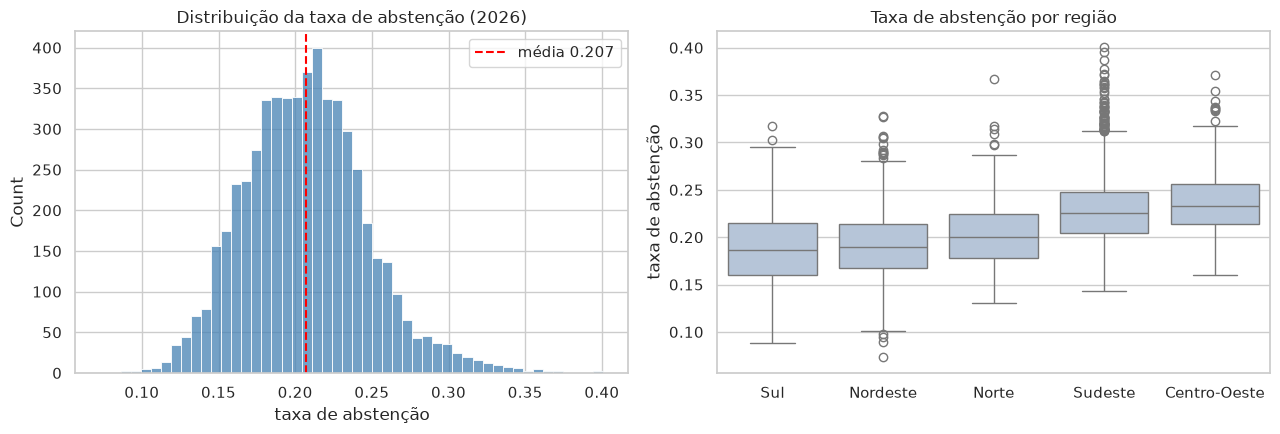

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(dados[ALVO], bins=50, ax=eixos[0], color="steelblue")
eixos[0].axvline(dados[ALVO].mean(), color="red", linestyle="--", label=f"média {dados[ALVO].mean():.3f}")
eixos[0].set(title="Distribuição da taxa de abstenção (2026)", xlabel="taxa de abstenção")
eixos[0].legend()
ordem = dados.groupby("regiao")[ALVO].median().sort_values().index
sns.boxplot(data=dados, x="regiao", y=ALVO, order=ordem, ax=eixos[1], color="lightsteelblue")
eixos[1].set(title="Taxa de abstenção por região", xlabel="", ylabel="taxa de abstenção")
plt.tight_layout()

A taxa de abstenção de 2026 tem média de cerca de **20,7%** e vai de 7% a 40%. Sudeste e Centro-Oeste se abstêm mais, Nordeste e Sul menos. Os cinco municípios com maior abstenção são todos de **Minas Gerais**, como mostra a próxima tabela.

In [9]:
colunas = ["nome", "sg_uf", ALVO, "abstencao_anterior"]
pd.concat({"maiores": dados.nlargest(5, ALVO)[colunas].reset_index(drop=True),
           "menores": dados.nsmallest(5, ALVO)[colunas].reset_index(drop=True)}, axis=1)

maiores                                          \
                      nome sg_uf taxa_abstencao abstencao_anterior   
0             Rio Vermelho    MG         0.4009             0.4056   
1  Santo Antônio Do Itambé    MG         0.3955             0.4039   
2      Serra Azul De Minas    MG         0.3871             0.3673   
3    Santa Maria Do Suaçuí    MG         0.3772             0.3626   
4         Chapada Do Norte    MG         0.3725             0.3840   

               menores                                          
                  nome sg_uf taxa_abstencao abstencao_anterior  
0  Bela Vista Do Piauí    PI         0.0731             0.0882  
1          Rio Fortuna    SC         0.0887             0.0962  
2    Jacobina Do Piauí    PI         0.0893             0.1075  
3   São José Do Sabugi    PB         0.0946             0.0976  
4    Aroeiras Do Itaim    PI         0.0974             0.0962

correlação: 0.806
variação média 2022 → 2026: -0.0055


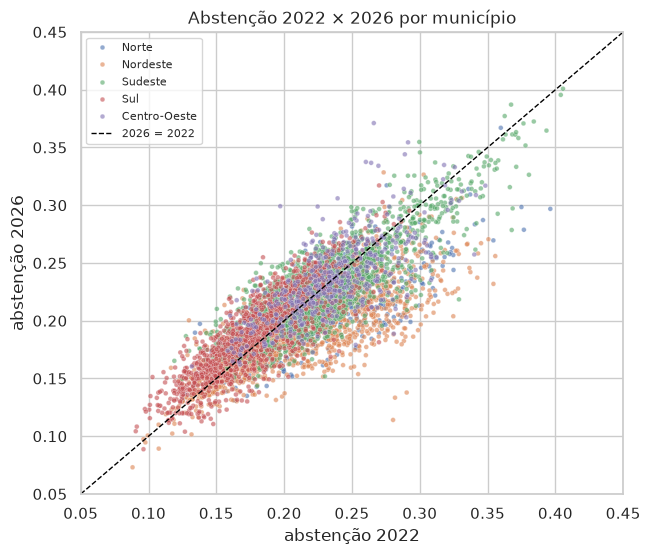

In [10]:
fig, eixo = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=dados, x="abstencao_anterior", y=ALVO, hue="regiao", s=12, alpha=0.6, ax=eixo)
limites = [0.05, 0.45]
eixo.plot(limites, limites, color="black", linestyle="--", linewidth=1, label="2026 = 2022")
eixo.set(xlim=limites, ylim=limites, xlabel="abstenção 2022", ylabel="abstenção 2026",
         title="Abstenção 2022 × 2026 por município")
eixo.legend(fontsize=8)
print(f"correlação: {dados[[ALVO, 'abstencao_anterior']].corr().iloc[0, 1]:.3f}")
print(f"variação média 2022 → 2026: {(dados[ALVO] - dados['abstencao_anterior']).mean():+.4f}")

A abstenção é **persistente**: a correlação entre 2022 e 2026 é de cerca de 0,81. Em média, ela caiu pouco mais de meio ponto percentual de uma eleição para a outra. Por isso "repetir 2022" é o baseline que o modelo precisa vencer.

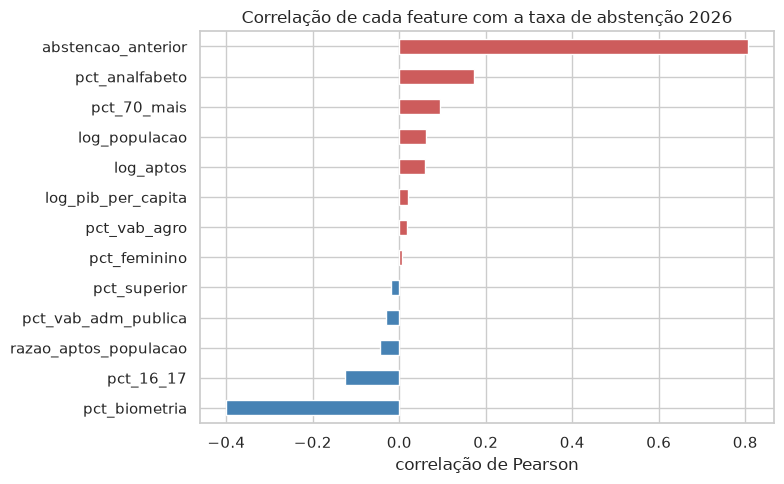

In [11]:
correlacoes = dados[FEATURES_NUMERICAS + [ALVO]].corr()[ALVO].drop(ALVO).sort_values()
fig, eixo = plt.subplots(figsize=(8, 5))
correlacoes.plot.barh(ax=eixo, color=np.where(correlacoes > 0, "indianred", "steelblue"))
eixo.set(title="Correlação de cada feature com a taxa de abstenção 2026", xlabel="correlação de Pearson")
plt.tight_layout()

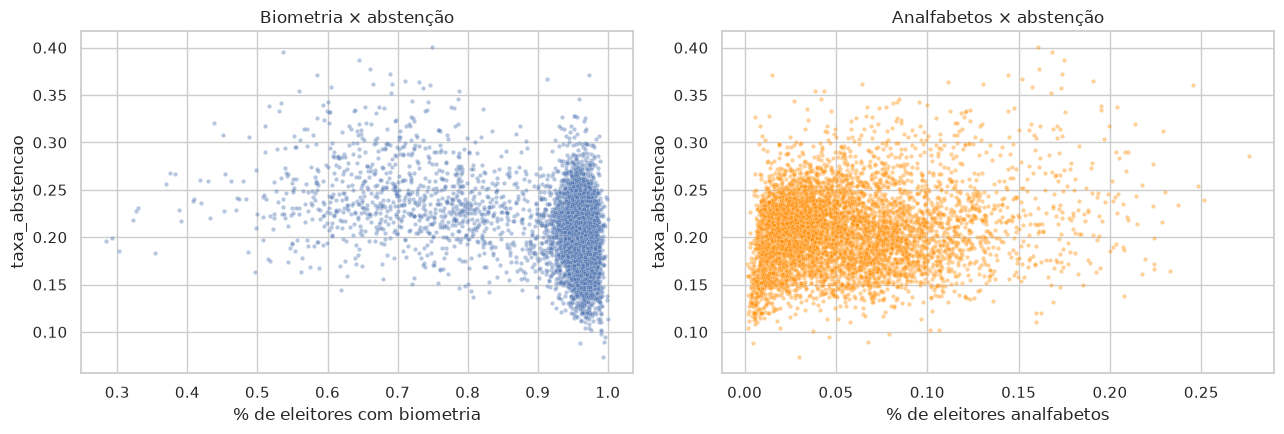

In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=dados, x="pct_biometria", y=ALVO, s=10, alpha=0.4, ax=eixos[0])
eixos[0].set(title="Biometria × abstenção", xlabel="% de eleitores com biometria")
sns.scatterplot(data=dados, x="pct_analfabeto", y=ALVO, s=10, alpha=0.4, ax=eixos[1], color="darkorange")
eixos[1].set(title="Analfabetos × abstenção", xlabel="% de eleitores analfabetos")
plt.tight_layout()

Duas relações chamam atenção além do histórico:
- **Biometria** (correlação de cerca de −0,40): municípios com mais eleitores cadastrados na biometria se abstêm menos. Uma explicação plausível é que a revisão biométrica cancela títulos de quem já não vota ou se mudou, o que "limpa" o cadastro de aptos.
- **Analfabetos** (+0,17) e **70+** (+0,09): os dois grupos são **eleitores facultativos** e puxam a abstenção para cima.

### Amapá

Recorte regional, mantendo o tema amazônico dos labs.

In [13]:
dados[dados["sg_uf"] == "AP"][["nome", "aptos", ALVO, "abstencao_anterior", "pct_biometria"]] \
    .sort_values(ALVO, ascending=False).reset_index(drop=True)

,nome,aptos,taxa_abstencao,abstencao_anterior,pct_biometria
0,Pedra Branca Do Amapari,9909,0.2816,0.2500,0.9671
1,Oiapoque,24220,0.2768,0.3166,0.9567
2,Serra Do Navio,4111,0.2605,0.2156,0.9688
3,Laranjal Do Jari,28170,0.2504,0.2642,0.9825
4,Vitória Do Jari,10405,0.2243,0.2345,0.9919
5,Calçoene,8907,0.2131,0.2435,0.9707
6,Porto Grande,15533,0.2057,0.2527,0.9755
7,Ferreira Gomes,7861,0.2037,0.1719,0.9812
8,Tartarugalzinho,11437,0.1891,0.2116,0.9639
9,Pracuúba,4022,0.1763,0.1730,0.9861


## 5. Feature Engineering

| Feature | Origem | Descrição |
|---|---|---|
| `abstencao_anterior` | TSE 2022 | taxa de abstenção do município no 1º turno de 2022 |
| `pct_16_17` | perfil TSE | % de eleitores de 16 e 17 anos (facultativos) |
| `pct_70_mais` | perfil TSE | % de eleitores com 70 anos ou mais (facultativos) |
| `pct_analfabeto` | perfil TSE | % de eleitores analfabetos (facultativos) |
| `pct_superior` | perfil TSE | % com superior completo |
| `pct_feminino` | perfil TSE | % de mulheres |
| `pct_biometria` | perfil TSE | % de eleitores com biometria cadastrada |
| `log_aptos` | TSE 2026 | log do número de eleitores aptos (porte do eleitorado) |
| `log_populacao` | IBGE Censo 2022 | log da população residente |
| `log_pib_per_capita` | IBGE 2023 | log do PIB per capita |
| `pct_vab_agro` | IBGE 2021 | participação da agropecuária no valor adicionado |
| `pct_vab_adm_publica` | IBGE 2021 | participação da administração pública no valor adicionado |
| `razao_aptos_populacao` | TSE + IBGE | aptos ÷ população: acima do esperado indica eleitores que se mudaram e continuam inscritos |
| `sg_uf` | TSE | UF, com One-Hot Encoding |

Cuidados contra vazamento (*leakage*):
- Nenhuma feature usa comparecimento, votos ou abstenção de 2026.
- O número de aptos e o perfil são fechados **antes** da eleição (o perfil é de julho/2026).
- O `StandardScaler` e o `OneHotEncoder` ficam **dentro do `Pipeline`**, então são ajustados só no treino de cada fold.

Os logs reduzem a assimetria de população, aptos e PIB, que vão de centenas a milhões.

In [14]:
dados[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
abstencao_anterior,5569.0000,0.2127,0.0472,0.0882,0.1789,0.2105,0.2416,0.4056
pct_16_17,5569.0000,0.0140,0.0073,0.0012,0.0078,0.0128,0.0193,0.0568
pct_70_mais,5569.0000,0.1146,0.0295,0.0262,0.0939,0.1133,0.1327,0.2749
pct_analfabeto,5569.0000,0.0561,0.0406,0.0012,0.0248,0.0464,0.0772,0.2760
pct_superior,5569.0000,0.0746,0.0370,0.0149,0.0469,0.0656,0.0943,0.3656
pct_feminino,5569.0000,0.5079,0.0174,0.4344,0.4962,0.5087,0.5201,0.5566
pct_biometria,5569.0000,0.9147,0.1063,0.2837,0.9346,0.9557,0.9684,1.0000
log_aptos,5569.0000,9.2908,1.0918,6.9976,8.4947,9.1384,9.8834,16.0287
log_populacao,5569.0000,9.4423,1.1844,6.7250,8.5618,9.3116,10.1035,16.2537
log_pib_per_capita,5569.0000,10.3306,0.6976,8.9491,9.7305,10.3054,10.8157,13.4904


## 6. Treinamento e avaliação

- Split **80/20** aleatório com semente 42 (4.455 municípios no treino e 1.114 no teste).
- **Validação cruzada de 5 folds** no treino para escolher o modelo, pelo menor RMSE médio.
- Três modelos: **Linear Regression**, **Random Forest** e **Gradient Boosting** (`HistGradientBoostingRegressor`).
- Dois baselines no mesmo conjunto de teste: **"média"** (prevê a média do treino) e **"repetir 2022"** (prevê a abstenção anterior).

In [15]:
resultado = modelo_service.treinar_e_avaliar(dados)
print(f"Modelo escolhido: {resultado.nome_melhor}")
resultado.metricas

Modelo escolhido: Gradient Boosting


,rmse_cv,rmse_teste,mae_teste,r2_teste
modelo,,,,
Baseline: média,NaN,0.0395,0.0311,-0.0000
Baseline: repetir 2022,NaN,0.0281,0.0211,0.4929
Linear Regression,0.0195,0.0186,0.0147,0.7773
Random Forest,0.0187,0.0179,0.0137,0.7955
Gradient Boosting,0.0180,0.0171,0.0132,0.8122


Redução do RMSE em relação a 'repetir 2022': 39.1%


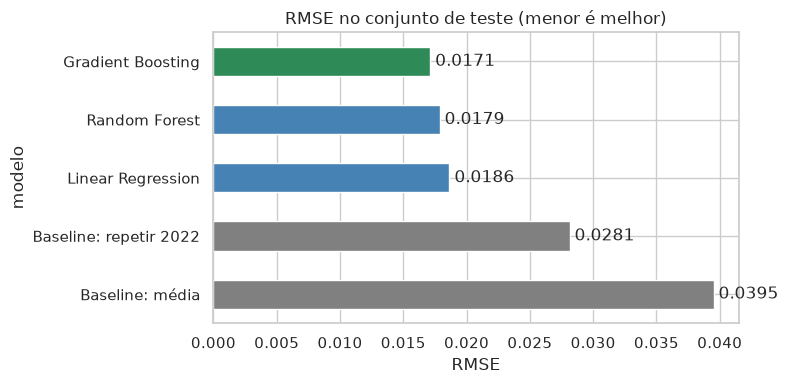

In [16]:
fig, eixo = plt.subplots(figsize=(8, 4))
metricas = resultado.metricas.sort_values("rmse_teste")
cores = ["seagreen" if nome == resultado.nome_melhor else ("gray" if nome.startswith("Baseline") else "steelblue")
         for nome in metricas.index]
metricas["rmse_teste"].plot.barh(ax=eixo, color=cores)
eixo.invert_yaxis()
eixo.set(title="RMSE no conjunto de teste (menor é melhor)", xlabel="RMSE")
for i, valor in enumerate(metricas["rmse_teste"]):
    eixo.text(valor, i, f" {valor:.4f}", va="center")
plt.tight_layout()

baseline = resultado.metricas.loc["Baseline: repetir 2022", "rmse_teste"]
melhor = resultado.metricas.loc[resultado.nome_melhor, "rmse_teste"]
print(f"Redução do RMSE em relação a 'repetir 2022': {(1 - melhor / baseline):.1%}")

## 7. Análise do modelo

resíduo médio: -0.0001 | 90% dos erros abaixo de 0.0288


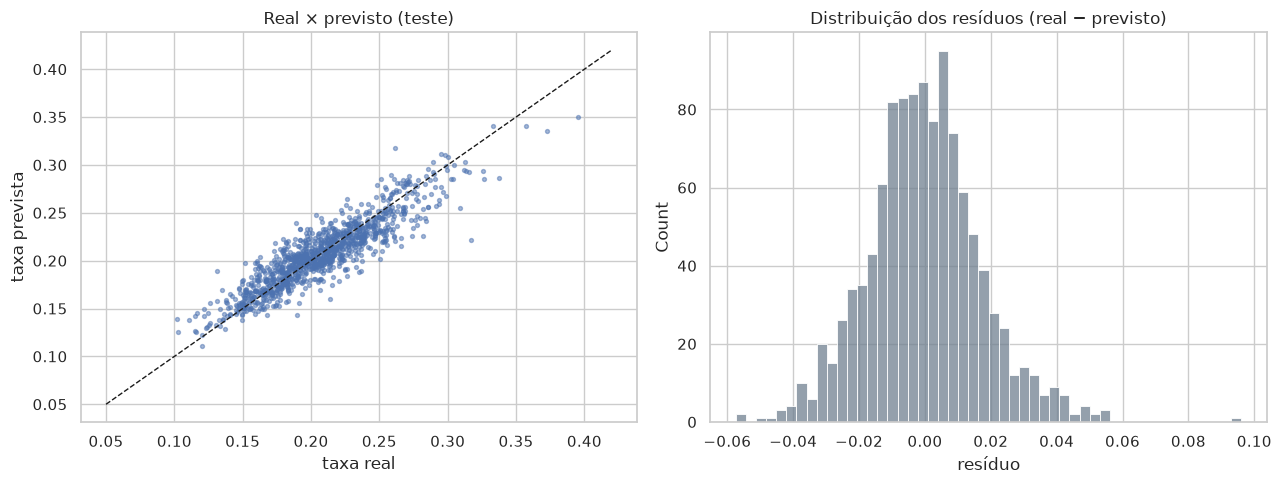

In [17]:
residuos = resultado.y_teste - resultado.previsto_teste
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
eixos[0].scatter(resultado.y_teste, resultado.previsto_teste, s=8, alpha=0.5)
eixos[0].plot([0.05, 0.42], [0.05, 0.42], "k--", linewidth=1)
eixos[0].set(title="Real × previsto (teste)", xlabel="taxa real", ylabel="taxa prevista")
sns.histplot(residuos, bins=50, ax=eixos[1], color="slategray")
eixos[1].set(title="Distribuição dos resíduos (real − previsto)", xlabel="resíduo")
plt.tight_layout()
print(f"resíduo médio: {residuos.mean():+.4f} | 90% dos erros abaixo de {residuos.abs().quantile(0.9):.4f}")

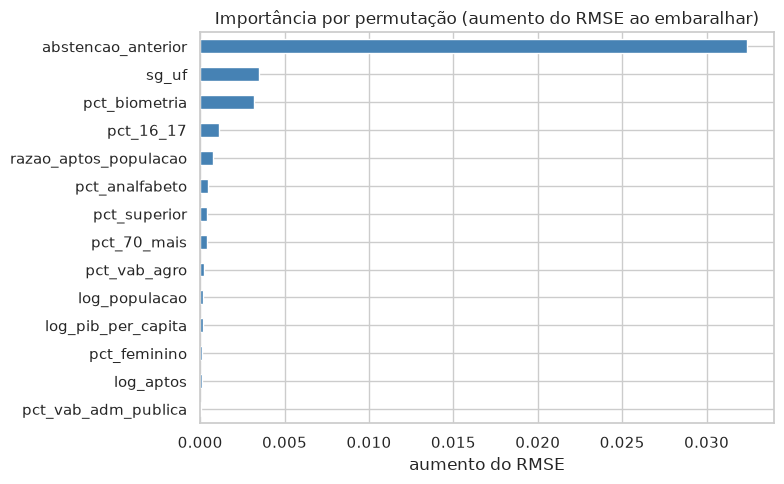

In [18]:
importancia = permutation_importance(
    resultado.modelo, resultado.x_teste, resultado.y_teste,
    n_repeats=10, random_state=42, scoring="neg_root_mean_squared_error",
)
importancias = pd.Series(importancia.importances_mean, index=FEATURES).sort_values()
fig, eixo = plt.subplots(figsize=(8, 5))
importancias.plot.barh(ax=eixo, color="steelblue")
eixo.set(title="Importância por permutação (aumento do RMSE ao embaralhar)", xlabel="aumento do RMSE")
plt.tight_layout()

In [19]:
teste = dados.loc[resultado.x_teste.index, ["nome", "sg_uf", ALVO, "abstencao_anterior"]]
teste["previsto"] = resultado.previsto_teste
teste["erro"] = teste[ALVO] - teste["previsto"]
teste.reindex(teste["erro"].abs().sort_values(ascending=False).index).head(8)

,nome,sg_uf,taxa_abstencao,abstencao_anterior,previsto,erro
95,Eirunepé,AM,0.3172,0.2755,0.2211,0.0961
1033,Pires Ferreira,CE,0.1314,0.1939,0.1888,-0.0575
297,Pedra Branca Do Amapari,AP,0.2816,0.2500,0.2257,0.0559
3011,Sardoá,MG,0.2616,0.3410,0.3172,-0.0557
811,Paes Landim,PI,0.2136,0.1560,0.1594,0.0542
107,Jutaí,AM,0.3093,0.3371,0.2555,0.0538
5171,Santa Rita Do Pardo,MS,0.3375,0.2602,0.2863,0.0511
5531,Santa Terezinha De Goiás,GO,0.2656,0.2158,0.2155,0.0501


## 8. Persistência: modelo e previsões

O melhor modelo é salvo com o pré-processamento em `models/modelo_abstencao_v1.pkl`, e as métricas vão para `models/metricas_v1.json`. As previsões dos 5.569 municípios modelados são gravadas na tabela `previsao` do PostgreSQL. É o mesmo que `POST /pipeline/treino` faz pelo worker.

In [20]:
caminho = modelo_service.salvar_modelo(resultado)
total = modelo_service.gravar_previsoes(db, resultado.modelo, dados)
print(f"modelo salvo em {caminho.name}; {total} previsões gravadas")
pd.read_sql(text('''
    SELECT m.nome, m.sg_uf, r.abstencoes::float8 / r.aptos AS real, p.taxa_prevista
    FROM previsao p
    JOIN municipio m USING (cd_ibge)
    JOIN resultado_eleicao r ON r.cd_ibge = p.cd_ibge AND r.ano = 2026
    WHERE m.sg_uf = 'AP' ORDER BY m.nome
'''), db.connection())

modelo salvo em modelo_abstencao_v1.pkl; 5569 previsões gravadas


,nome,sg_uf,real,taxa_prevista
0,Amapá,AP,0.1676,0.1934
1,Calçoene,AP,0.2131,0.2226
2,Cutias,AP,0.1760,0.1758
3,Ferreira Gomes,AP,0.2037,0.1933
4,Itaubal,AP,0.1719,0.1830
5,Laranjal Do Jari,AP,0.2504,0.2241
6,Macapá,AP,0.1588,0.1742
7,Mazagão,AP,0.1451,0.1428
8,Oiapoque,AP,0.2768,0.2720
9,Pedra Branca Do Amapari,AP,0.2816,0.2257


A API (`uv run uvicorn abstencao.main:app`) disponibiliza o mesmo modelo:
- `GET /municipios/1600303` devolve dados de Macapá com a taxa real e a prevista.
- `POST /prever` recebe as features de um município e devolve a taxa prevista.

In [21]:
exemplo = dados[dados["nome"] == "Oiapoque"][features_service.COLUNAS_ENTRADA].iloc[0].to_dict()
print("Oiapoque, previsão via modelo_service.prever:", round(modelo_service.prever(exemplo), 4))
print("Oiapoque, taxa real em 2026:", round(dados.loc[dados['nome'] == 'Oiapoque', ALVO].iloc[0], 4))
db.close()

Oiapoque, previsão via modelo_service.prever: 0.272
Oiapoque, taxa real em 2026: 0.2768


## 9. Conclusões

- O pipeline integra **4 fontes** (3 do TSE em CSV dentro de ZIP e a API JSON do IBGE) em um modelo relacional no **PostgreSQL**, com ETL em Python, log de cargas, migrations versionadas (Alembic), worker assíncrono (Arq) e API (FastAPI).
- O **Gradient Boosting** teve o menor erro, com **RMSE ≈ 0,0171** (cerca de 1,7 ponto percentual) e **R² ≈ 0,81** no teste. É uma redução de **cerca de 39%** no erro em relação a "repetir 2022" (RMSE ≈ 0,0281) e de mais da metade em relação a "prever a média" (RMSE ≈ 0,0395).
- O histórico explica a maior parte do resultado, mas não tudo. **UF**, **biometria** e o peso dos **eleitores facultativos** (16–17 anos, 70+ e analfabetos) acrescentam sinal real. Os indicadores econômicos do IBGE pesam pouco depois que o perfil do eleitorado entra.
- Os maiores erros estão em municípios pequenos com saltos atípicos entre 2022 e 2026 (por exemplo, Eirunepé-AM, Pires Ferreira-CE e Pedra Branca do Amapari-AP). Fatores locais, como disputa acirrada, clima ou acesso às seções, não estão nos dados.

**Limitações e próximos passos:**
- Boa Esperança do Norte (MT), sem histórico, e Cachoeira Dourada (GO), com VAB total negativo, ficaram fora da modelagem.
- O split é aleatório entre municípios da mesma eleição. Uma validação mais exigente seria treinar em 2018 → 2022 e testar em 2022 → 2026, como na discussão de *drift* do M5.
- Features promissoras: distância média até a seção eleitoral, competitividade da disputa local e dados de transporte e clima no dia da eleição.